 # 05 Drive-Cycle Parameter-Set Comparison

 Compare PyBaMM parameter sets using both SPMe and DFN models with the same SEI degradation options.

In [1]:
%pip install "pybamm<=23.9" "numpy<2.0,>=1.26.4" "pandas<2.0" liionpack matplotlib scipy

# MAKE SURE YOU ARE ON PYTHON 3.11 NO NEWER

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
import liionpack as lp

# Enable inline plotting for Jupyter
%matplotlib inline


In [3]:
# Load all recorded columns; set N_SAMPLES=100 for a short smoke test.
# Increase N_CYCLE_REPEATS to study cumulative degradation over repeated cycles.
N_SAMPLES = 100
N_CYCLE_REPEATS = 1

drive_cycle_path = "../../../../../../../workspaces/liionpacktesting/data/ioniq.csv"
full_cycle = pd.read_csv(drive_cycle_path, comment="#").to_numpy()
if N_SAMPLES is not None:
    full_cycle = full_cycle[:N_SAMPLES]

# The CSV columns are Time, Current, Voltage, SoC, and SoH.
drive_cycle = full_cycle[:, :2].copy()
cycle_dt = float(np.median(np.diff(drive_cycle[:, 0])))
cycle_duration = drive_cycle[-1, 0] - drive_cycle[0, 0] + cycle_dt
if N_CYCLE_REPEATS > 1:
    drive_cycle = np.vstack([
        np.column_stack((drive_cycle[:, 0] + repeat * cycle_duration, drive_cycle[:, 1]))
        for repeat in range(N_CYCLE_REPEATS)
    ])

 Let's have a look at the drive cycle. The first column is the time stamp and the second is the current.

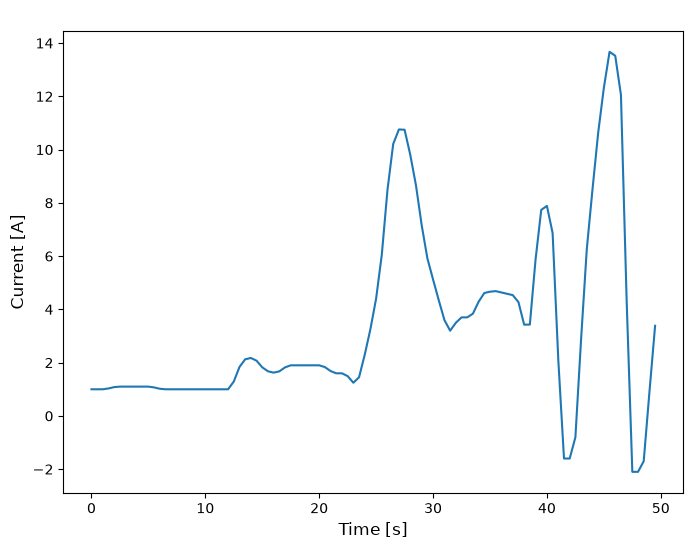

In [4]:
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'none'
    plt.rcParams['axes.facecolor'] = 'none'
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(drive_cycle[:, 0], drive_cycle[:, 1])
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Current [A]")
    ax.set_title("Pack Drive Cycle Current")
    
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)
        
    plt.show()


 Set up the drive-cycle pack and the candidate parameter sets. The 180s2p circuit is retained for comparison; parameter sets are cell models and are not Ioniq 5 calibrations.

In [5]:
Np = 2
Ns = 180
netlist = lp.setup_circuit(Np=Np, Ns=Ns, Rb=1e-4, Rc=1e-3, Ri=5e-2, V=4.0, I=14.0)

# Built-in presets are different cell formats; compare them at equal C-rate.
parameter_set_names = ["Chen2020", "Ecker2015", "Marquis2019"]
initial_soc = 0.965
reference_capacity = float(
    pybamm.ParameterValues("Chen2020")["Nominal cell capacity [A.h]"]
)

# Use identical degradation mechanisms for every parameter set and model.
aging_options = {
    "SEI": "ec reaction limited",
    "SEI film resistance": "distributed",
    "SEI porosity change": "true",
}
aging_variables = [
    "X-averaged negative total SEI thickness [m]",
    "Loss of capacity to negative SEI [A.h]",
    "Loss of capacity to positive SEI [A.h]",
]
voltage_cutoffs = {
    "Upper voltage cut-off [V]": 4.50,
    "Lower voltage cut-off [V]": 2.5,
}

 ## Run SPMe and DFN for Each Parameter Set

 Each preset gets a fresh parameter-values object for each solve. SPMe runs through liionpack across the pack; DFN runs as a single cell with the current divided by Np.

In [6]:
parameter_set_results = {}
for preset_name in parameter_set_names:
    print(f"Running {preset_name}: SPMe + SEI")
    spme_parameters = pybamm.ParameterValues(preset_name)
    spme_parameters.update(voltage_cutoffs)
    nominal_capacity = float(spme_parameters["Nominal cell capacity [A.h]"])
    current_scale = nominal_capacity / reference_capacity

    # Keep the applied C-rate consistent across cell parameter sets.
    preset_drive_cycle = drive_cycle.copy()
    preset_drive_cycle[:, 1] *= current_scale
    preset_experiment = pybamm.Experiment(
        [pybamm.step.current(preset_drive_cycle)],
        period="0.5 second",
    )

    def spme_sim_func(parameter_values):
        model = pybamm.lithium_ion.SPMe(options=aging_options)
        model = lp.add_events_to_model(model)
        return pybamm.Simulation(
            model,
            parameter_values=parameter_values,
            experiment=preset_experiment,
            solver=pybamm.CasadiSolver(mode="safe"),
        )

    spme_output = lp.solve(
        netlist=netlist.copy(deep=True),
        parameter_values=spme_parameters,
        experiment=preset_experiment,
        initial_soc=initial_soc,
        sim_func=spme_sim_func,
        output_variables=aging_variables,
    )

    print(f"Running {preset_name}: DFN + SEI")
    dfn_parameters = pybamm.ParameterValues(preset_name)
    dfn_parameters.update(voltage_cutoffs)
    cell_drive_cycle = preset_drive_cycle.copy()
    cell_drive_cycle[:, 1] /= Np
    dfn_experiment = pybamm.Experiment(
        [pybamm.step.current(cell_drive_cycle)],
        period="0.5 second",
    )
    dfn_model = pybamm.lithium_ion.DFN(options=aging_options)
    dfn_sim = pybamm.Simulation(
        dfn_model,
        parameter_values=dfn_parameters,
        experiment=dfn_experiment,
        solver=pybamm.CasadiSolver(mode="safe", dt_max=0.5),
    )
    dfn_solution = dfn_sim.solve(initial_soc=initial_soc)

    parameter_set_results[preset_name] = {
        "nominal_capacity": nominal_capacity,
        "current_scale": current_scale,
        "spme": spme_output,
        "dfn": dfn_solution,
    }

Running Chen2020: SPMe + SEI


Stepping simulation: 100%|██████████| 100/100 [04:14<00:00,  2.54s/it]


Running Chen2020: DFN + SEI
Running Ecker2015: SPMe + SEI


Stepping simulation: 100%|██████████| 100/100 [04:32<00:00,  2.73s/it]


Running Ecker2015: DFN + SEI
Running Marquis2019: SPMe + SEI


Stepping simulation: 100%|██████████| 100/100 [03:48<00:00,  2.28s/it]


Running Marquis2019: DFN + SEI


 ## Compare Voltage and SEI-Based SOH by Parameter Set

 Each preset has an SPMe pack result and a lumped DFN result. Input current is scaled per preset so each cell model sees the same C-rate as Chen2020. Recorded voltage and SoH are shown as references; the voltage trace reflects the original vehicle load, not each scaled preset load.

In [7]:
# Align voltage and SEI-based SOH traces for each parameter set

t_recorded = np.asarray(full_cycle[:, 0], dtype=float)
soh_recorded = np.asarray(full_cycle[:, -1], dtype=float)
recorded_order = np.argsort(t_recorded)
t_recorded = t_recorded[recorded_order]
soh_recorded = soh_recorded[recorded_order]

comparison_results = {}
for preset_name, result in parameter_set_results.items():
    spme_output = result["spme"]
    dfn_solution = result["dfn"]
    nominal_capacity = result["nominal_capacity"]

    t_pack = np.asarray(spme_output["Time [s]"])
    v_spme = np.mean(np.asarray(spme_output["Terminal voltage [V]"], dtype=float), axis=1)
    sei_loss_spme = (
        np.asarray(spme_output["Loss of capacity to negative SEI [A.h]"])
        + np.asarray(spme_output["Loss of capacity to positive SEI [A.h]"])
    )
    soh_spme_cells = 100 * (
        1 - (sei_loss_spme - sei_loss_spme[0, :]) / nominal_capacity
    )
    soh_spme = np.mean(soh_spme_cells, axis=1)

    t_dfn = np.asarray(dfn_solution["Time [s]"].entries)
    v_dfn_raw = np.asarray(dfn_solution["Terminal voltage [V]"].entries)
    sei_loss_dfn = (
        np.asarray(dfn_solution["Loss of capacity to negative SEI [A.h]"].entries)
        + np.asarray(dfn_solution["Loss of capacity to positive SEI [A.h]"].entries)
    )
    soh_dfn_raw = 100 * (
        1 - (sei_loss_dfn - sei_loss_dfn[0]) / nominal_capacity
    )
    dfn_order = np.argsort(t_dfn)
    t_dfn = t_dfn[dfn_order]
    v_dfn_raw = v_dfn_raw[dfn_order]
    soh_dfn_raw = soh_dfn_raw[dfn_order]

    dt = np.median(np.diff(t_pack))
    t_dfn_shifted = t_dfn + dt
    v_dfn = np.interp(t_pack, t_dfn_shifted, v_dfn_raw)
    soh_dfn = np.interp(t_pack, t_dfn_shifted, soh_dfn_raw)

    comparison_results[preset_name] = {
        "time": t_pack,
        "v_spme": v_spme,
        "v_dfn": v_dfn,
        "soh_spme": soh_spme,
        "soh_dfn": soh_dfn,
    }

In [8]:
# Summarize each preset's normalized load and final model outputs
for preset_name, result in parameter_set_results.items():
    comparison = comparison_results[preset_name]
    print(f"{preset_name}: nominal capacity = {result['nominal_capacity']:.5g} A.h")
    print(f"  Applied current scale: {result['current_scale']:.5g}x Chen2020")
    print(f"  Final SPMe voltage: {comparison['v_spme'][-1]:.4f} V")
    print(f"  Final DFN voltage:  {comparison['v_dfn'][-1]:.4f} V")
    print(f"  Final SPMe SEI-based SOH: {comparison['soh_spme'][-1]:.6f}%")
    print(f"  Final DFN SEI-based SOH:  {comparison['soh_dfn'][-1]:.6f}%")

Chen2020: nominal capacity = 5 A.h
  Applied current scale: 1x Chen2020
  Final SPMe voltage: 4.0882 V
  Final DFN voltage:  4.0820 V
  Final SPMe SEI-based SOH: 99.949417%
  Final DFN SEI-based SOH:  99.952897%
Ecker2015: nominal capacity = 0.15625 A.h
  Applied current scale: 0.03125x Chen2020
  Final SPMe voltage: 4.1407 V
  Final DFN voltage:  4.1404 V
  Final SPMe SEI-based SOH: 99.962784%
  Final DFN SEI-based SOH:  99.963229%
Marquis2019: nominal capacity = 0.68062 A.h
  Applied current scale: 0.13612x Chen2020
  Final SPMe voltage: 4.0096 V
  Final DFN voltage:  4.0090 V
  Final SPMe SEI-based SOH: 99.925980%
  Final DFN SEI-based SOH:  99.926896%


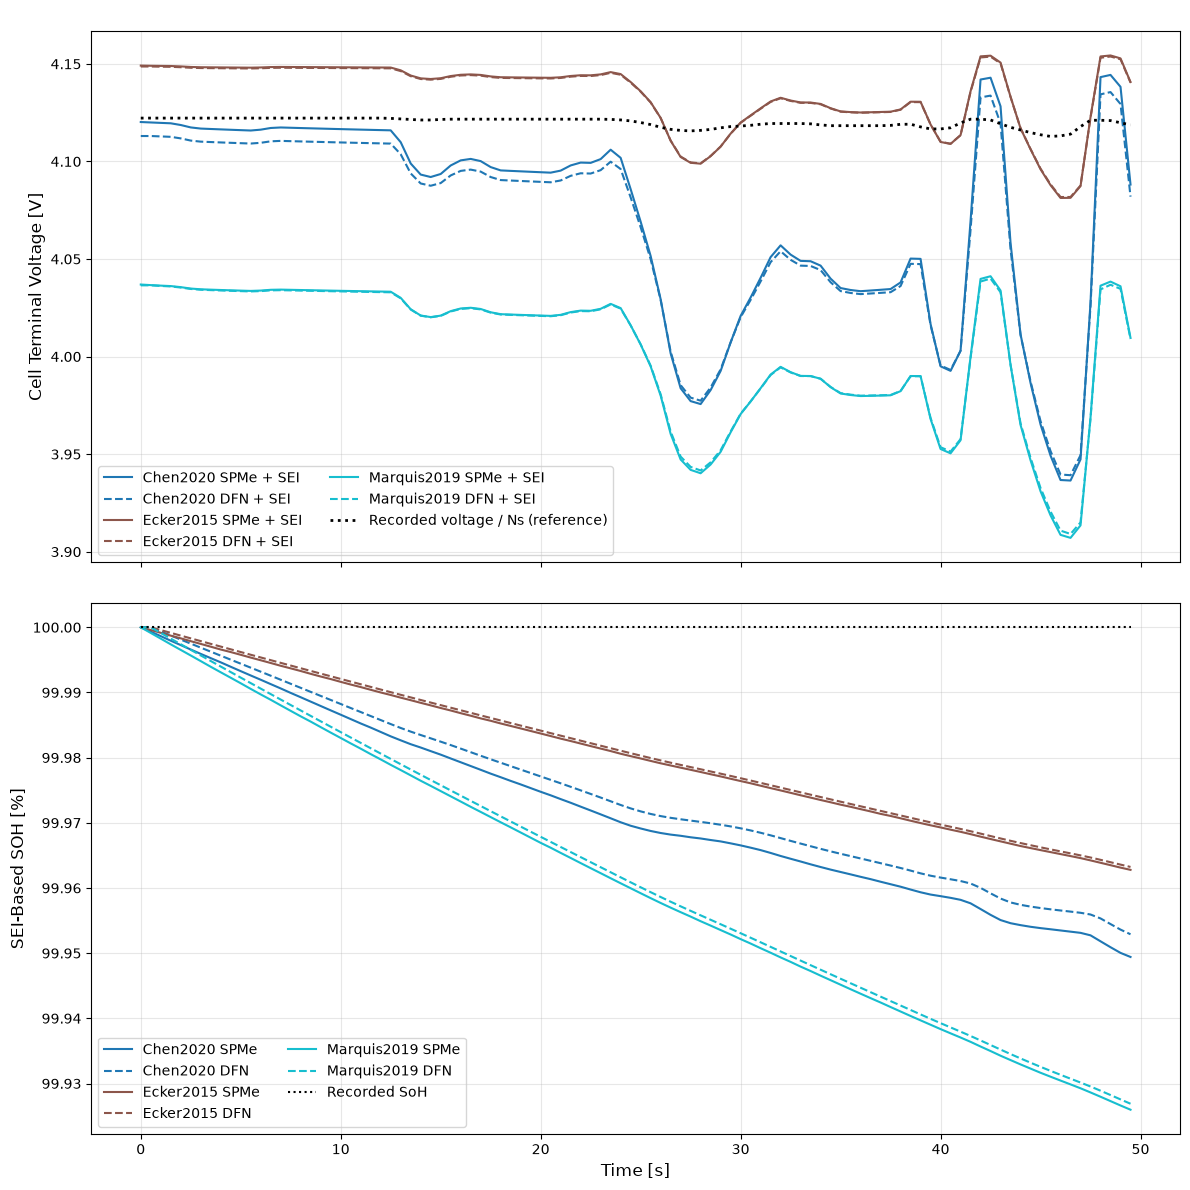

In [11]:
# Compare cell voltage and SEI-based SOH by parameter set
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'none'
    plt.rcParams['axes.facecolor'] = 'none'
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 12),
        gridspec_kw={'height_ratios': [1, 1]},
        sharex=True,
    )
    preset_colors = plt.cm.tab10(np.linspace(0, 1, len(parameter_set_names)))

    for color, preset_name in zip(preset_colors, parameter_set_names):
        result = comparison_results[preset_name]
        time = result["time"]
        ax1.plot(
            time, result["v_spme"], color=color, linestyle="-",
            label=f"{preset_name} SPMe + SEI",
        )
        ax1.plot(
            time, result["v_dfn"], color=color, linestyle="--",
            label=f"{preset_name} DFN + SEI",
        )
        ax2.plot(
            time, result["soh_spme"], color=color, linestyle="-",
            label=f"{preset_name} SPMe",
        )
        ax2.plot(
            time, result["soh_dfn"], color=color, linestyle="--",
            label=f"{preset_name} DFN",
        )

    # Recorded voltage is pack voltage; divide by Ns to match cell voltage scale.
    ax1.plot(
        full_cycle[:, 0], full_cycle[:, 2] / Ns,
        color="black", linestyle=":", linewidth=2,
        label="Recorded voltage / Ns (reference)",
    )
    ax1.set_ylabel("Cell Terminal Voltage [V]")
    ax1.set_title("Voltage by Parameter Set (Equal C-Rate)")
    ax1.legend(ncol=2)
    ax1.grid(True, alpha=0.3)

    ax2.plot(
        t_recorded, soh_recorded, color="black", linestyle=":",
        label="Recorded SoH",
    )
    ax2.set_xlabel("Time [s]")
    ax2.set_ylabel("SEI-Based SOH [%]")
    ax2.set_title("SEI-Based SOH by Parameter Set")
    ax2.legend(ncol=2)
    ax2.grid(True, alpha=0.3)

    for ax in [ax1, ax2]:
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_visible(True)

    plt.tight_layout()
    plt.show()

 *This is a parameter-set sensitivity comparison, not an Ioniq 5 calibration: Chen2020, Ecker2015, and Marquis2019 describe different published cells and may differ in chemistry and nominal capacity. Each SOH curve is an SEI-only capacity-loss estimate normalized by its own set's nominal cell capacity; it excludes lithium plating and loss of active material. Keep `N_SAMPLES=100` for a quick smoke test; use `None` and increase `N_CYCLE_REPEATS` for a longer aging comparison.*